<a href="https://colab.research.google.com/github/Kufala/Fraud-Detection/blob/main/Sales_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np

In [ ]:
df=pd.read_csv('/content/SuperMarket Analysis.csv')

In [ ]:
df.head()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Sales,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,Alex,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,1:08:00 PM,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,Giza,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29:00 AM,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,Alex,Yangon,Normal,Female,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,1:23:00 PM,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,Alex,Yangon,Member,Female,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,8:33:00 PM,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,Alex,Yangon,Member,Female,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37:00 AM,Ewallet,604.17,4.761905,30.2085,5.3


In [ ]:
df.isna().sum()

,0
Invoice ID,0
Branch,0
City,0
Customer type,0
Gender,0
Product line,0
Unit price,0
Quantity,0
Tax 5%,0
Sales,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Invoice ID               1000 non-null   object 
 1   Branch                   1000 non-null   object 
 2   City                     1000 non-null   object 
 3   Customer type            1000 non-null   object 
 4   Gender                   1000 non-null   object 
 5   Product line             1000 non-null   object 
 6   Unit price               1000 non-null   float64
 7   Quantity                 1000 non-null   int64  
 8   Tax 5%                   1000 non-null   float64
 9   Sales                    1000 non-null   float64
 10  Date                     1000 non-null   object 
 11  Time                     1000 non-null   object 
 12  Payment                  1000 non-null   object 
 13  cogs                     1000 non-null   float64
 14  gross margin percentage  

In [ ]:
# Add a rank column (1 = highest sales)
df["Sales_Rank"] = df["Sales"].rank(ascending=False, method="dense").astype(int)

df['Sales_Rank'].head(10)


,Sales_Rank
0,186
1,846
2,381
3,234
4,133
5,142
6,286
7,68
8,864
9,640


In [ ]:
df.describe()

,Unit price,Quantity,Tax 5%,Sales,cogs,gross margin percentage,gross income,Rating,Sales_Rank
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1.000000e+03,1000.000000,1000.00000,1000.000000
mean,55.672130,5.510000,15.379369,322.966749,307.58738,4.761905e+00,15.379369,6.97270,495.753000
std,26.494628,2.923431,11.708825,245.885335,234.17651,6.131498e-14,11.708825,1.71858,285.378477
min,10.080000,1.000000,0.508500,10.678500,10.17000,4.761905e+00,0.508500,4.00000,1.000000
25%,32.875000,3.000000,5.924875,124.422375,118.49750,4.761905e+00,5.924875,5.50000,249.750000
50%,55.230000,5.000000,12.088000,253.848000,241.76000,4.761905e+00,12.088000,7.00000,496.500000
75%,77.935000,8.000000,22.445250,471.350250,448.90500,4.761905e+00,22.445250,8.50000,742.250000
max,99.960000,10.000000,49.650000,1042.650000,993.00000,4.761905e+00,49.650000,10.00000,990.000000


In [ ]:
df.sort_values(by="Sales", ascending=False)

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Sales,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating,new_date,Sales_Rank,Highest_Sales
350,860-79-0874,Giza,Naypyitaw,Member,Female,Fashion accessories,99.30,10,49.6500,1042.6500,2/15/2019,2:53:00 PM,Credit card,993.00,4.761905,49.6500,6.6,2019-02-15,1,True
167,687-47-8271,Alex,Yangon,Normal,Male,Fashion accessories,98.98,10,49.4900,1039.2900,2/8/2019,4:20:00 PM,Credit card,989.80,4.761905,49.4900,8.7,2019-08-02,2,False
557,283-26-5248,Giza,Naypyitaw,Member,Female,Food and beverages,98.52,10,49.2600,1034.4600,1/30/2019,8:23:00 PM,Ewallet,985.20,4.761905,49.2600,4.5,2019-01-30,3,False
699,751-41-9720,Giza,Naypyitaw,Normal,Male,Home and lifestyle,97.50,10,48.7500,1023.7500,1/12/2019,4:18:00 PM,Ewallet,975.00,4.761905,48.7500,8.0,2019-12-01,4,False
996,303-96-2227,Cairo,Mandalay,Normal,Female,Home and lifestyle,97.38,10,48.6900,1022.4900,3/2/2019,5:16:00 PM,Ewallet,973.80,4.761905,48.6900,4.4,2019-02-03,5,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
402,236-86-3015,Giza,Naypyitaw,Member,Male,Home and lifestyle,13.98,1,0.6990,14.6790,2/4/2019,1:38:00 PM,Ewallet,13.98,4.761905,0.6990,9.8,2019-04-02,986,False
443,192-98-7397,Giza,Naypyitaw,Normal,Male,Fashion accessories,12.78,1,0.6390,13.4190,1/8/2019,2:11:00 PM,Ewallet,12.78,4.761905,0.6390,9.5,2019-08-01,987,False
223,279-62-1445,Giza,Naypyitaw,Member,Female,Fashion accessories,12.54,1,0.6270,13.1670,2/21/2019,12:38:00 PM,Cash,12.54,4.761905,0.6270,8.2,2019-02-21,988,False
629,308-39-1707,Alex,Yangon,Normal,Female,Fashion accessories,12.09,1,0.6045,12.6945,1/26/2019,6:19:00 PM,Credit card,12.09,4.761905,0.6045,8.2,2019-01-26,989,False


In [ ]:
# Select only City, Branch, and Sales columns
df_selected = df[["City", "Branch", "Sales"]]

print(df_selected)


          City Branch      Sales
0       Yangon   Alex   548.9715
1    Naypyitaw   Giza    80.2200
2       Yangon   Alex   340.5255
3       Yangon   Alex   489.0480
4       Yangon   Alex   634.3785
..         ...    ...        ...
995  Naypyitaw   Giza    42.3675
996   Mandalay  Cairo  1022.4900
997     Yangon   Alex    33.4320
998     Yangon   Alex    69.1110
999     Yangon   Alex   649.2990

[1000 rows x 3 columns]


In [ ]:
# Select only City, Branch, and Sales columns
df_selected = df[["City", "Branch", "Sales"]]

# Sort by Sales in descending order
df_sorted = df_selected.sort_values(by="Sales", ascending=False)

print(df_sorted)


          City Branch      Sales
350  Naypyitaw   Giza  1042.6500
167     Yangon   Alex  1039.2900
557  Naypyitaw   Giza  1034.4600
699  Naypyitaw   Giza  1023.7500
996   Mandalay  Cairo  1022.4900
..         ...    ...        ...
402  Naypyitaw   Giza    14.6790
443  Naypyitaw   Giza    13.4190
223  Naypyitaw   Giza    13.1670
629     Yangon   Alex    12.6945
822  Naypyitaw   Giza    10.6785

[1000 rows x 3 columns]


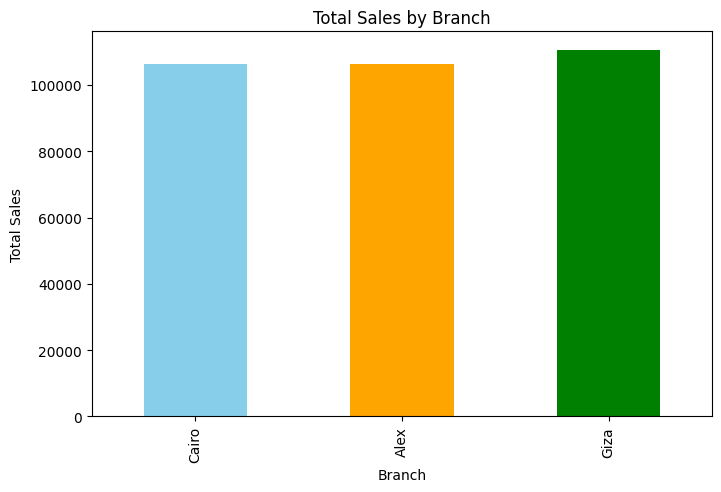

In [ ]:
# Aggregate sales by Branch (or you can use 'City')
import matplotlib.pyplot as plt

sales_by_branch = df.groupby('Branch')['Sales'].sum().sort_values()

colors = ['skyblue', 'orange', 'green']

# Plot bar chart
sales_by_branch.plot(kind='bar', color=colors, figsize=(8,5))
plt.title('Total Sales by Branch')
plt.xlabel('Branch')
plt.ylabel('Total Sales')
plt.show()


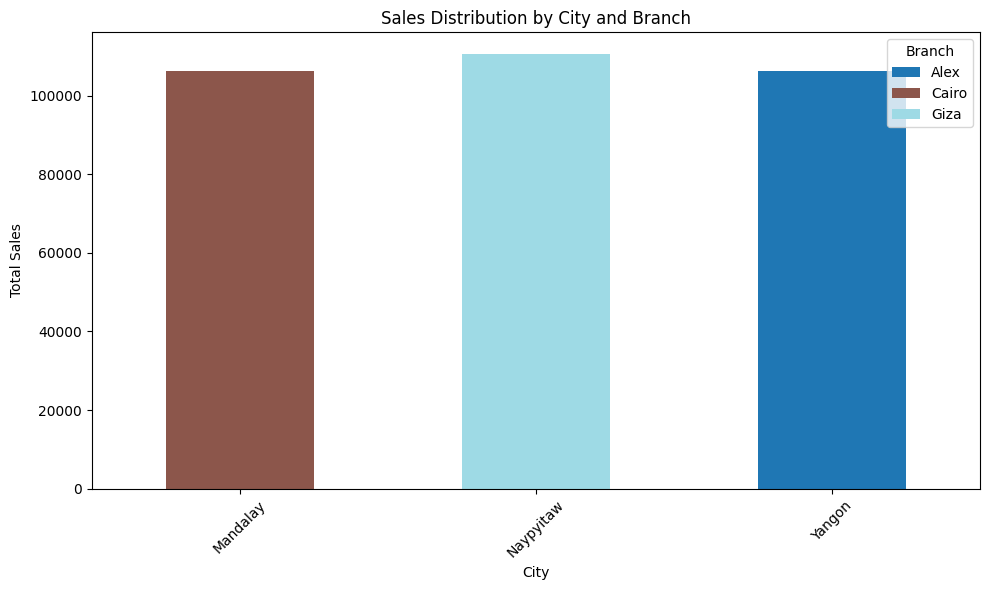

In [ ]:
# Pivot data to have Branch as columns and City as index
pivot_df = df.pivot_table(index='City', columns='Branch', values='Sales', aggfunc='sum', fill_value=0)

# Plot stacked bar chart
pivot_df.plot(kind='bar', stacked=True, figsize=(10,6), colormap='tab20')
plt.title('Sales Distribution by City and Branch')
plt.xlabel('City')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.legend(title='Branch')
plt.tight_layout()
plt.show()